# Matching methods

Starting point for the comparable-company matching. Treat one company as if it
were private, find comparable companies in the supplied list using only
non-financial information from websites, then estimate its EV/EBITDA multiple
from the comps.

**Rules this notebook follows**
- **Inputs:** name + website only (Aziz's rule). The text comes from the
  website scrape (`website_scrape/`, outputs in `outputs-local/website_scrape/`).
- **Financial fields stay out of the matching:** revenue, EBITDA, margin,
  debt/revenue and EV/EBITDA are loaded only in a method's valuation step,
  after its comps are chosen, and never feed the matching.
- **SIC codes** are loaded for checking results only.

Sections 1-2 load and describe the data. Each later section is one matching
method, ending with its valuation. Section 3: embeddings of the website text.

In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

# repo root = the folder holding data_manifest.json (works from the repo root or matching/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
sys.path.insert(0, str(ROOT / "website_scrape"))
from fetch_and_clean import load_companies          # non-financial columns only; also adds src/
from project_data import OUTPUTS_LOCAL, load_manifest, sha256, snapshot_path
from scrape_websites import DEFAULT_OUT as SCRAPE_OUT, output_paths

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---- settings -------------------------------------------------------------
TARGET = "PCTY"     # ticker of the company treated as private
# ---------------------------------------------------------------------------

OUT_ROOT = OUTPUTS_LOCAL / "matching"   # each run will write to OUT_ROOT / <run time>
manifest = load_manifest()
SNAPSHOT = manifest["required_snapshot"]
print("repo:", ROOT)
print("snapshot:", SNAPSHOT, manifest["snapshots"][SNAPSHOT]["sha256"][:12], "(checksum verified on load)")
print("scrape outputs:", SCRAPE_OUT)

repo: C:\Users\micha\Qual2Cast
snapshot: company_list_v3 3ab9a43e7426 (checksum verified on load)
scrape outputs: C:\Users\micha\Qual2Cast\outputs-local\website_scrape


## 1. Data

### Company list

The required snapshot (checksum-checked), with non-financial columns only.
SIC codes are 4-character, zero-padded strings.

In [2]:
companies = load_companies(str(snapshot_path()))
FINANCIAL = ["target_revenue", "target_ebitda", "target_margin",
             "target_debt_to_revenue", "target_ev_to_ebitda"]
assert not set(FINANCIAL) & set(companies.columns), "financial columns must not be loaded here"
print(len(companies), "companies;", list(companies.columns))
companies.head()

560 companies; ['IQ_COMPANY_ID', 'target_company_name', 'target_ciq_ticker', 'target_ciq_exchange', 'target_ciq_website', 'target_sic2_code', 'target_sic3_code', 'target_sic4_code', 'target_primary_sic_industry']


,IQ_COMPANY_ID,target_company_name,target_ciq_ticker,target_ciq_exchange,target_ciq_website,target_sic2_code,target_sic3_code,target_sic4_code,target_primary_sic_industry
0,IQ320500,"AAON, Inc.",AAON,NasdaqGS,www.aaon.com,35,358,3585,Air-Conditioning and Warm Air Heating Equipment and Commercial and Industrial Refrigeration Equipment
1,IQ168154,AAR Corp.,AIR,NYSE,www.aarcorp.com,50,508,5080,"Machinery, Equipment, And Supplies"
2,IQ310545,Acadian Asset Management Inc.,AAMI,NYSE,www.bsig.com,62,628,6282,Investment Advice
3,IQ327378336,"Accel Entertainment, Inc.",ACEL,NYSE,www.accelentertainment.com,79,799,7990,Miscellaneous Amusement And Recreation
4,IQ294382,"Accendra Health, Inc.",ACH,NYSE,www.accendrahealth.com,50,504,5047,"Medical, Dental, and Hospital Equipment and Supplies"


### Scraped pages

One row per page that was kept, with its cleaned text and source. This uses
the cleaned fields (`title`, `meta`, `blocks`). The raw text and the removal
log stay in the JSON files (see `website_scrape/README.md`).

In [3]:
page_dir = output_paths(SCRAPE_OUT).page_text
records = {p.stem: json.loads(p.read_text(encoding="utf-8")) for p in sorted(page_dir.glob("*.json"))}

pages = pd.DataFrame([
    {"IQ_COMPANY_ID": r["IQ_COMPANY_ID"], "page_id": pg["page_id"], "category": pg["category"],
     "url": pg["url"], "method": pg["method"], "wayback_snapshot": pg["snapshot"],
     "fetched_at": pg["fetched_at"], "words": pg["word_count"], "block_page": pg["block_page"],
     "text": "\n".join(x for x in [pg["title"], pg["meta"], *pg["blocks"]] if x)}
    for r in records.values() for pg in r["pages"]
])

company_text = (pages[~pages.block_page].groupby("IQ_COMPANY_ID")
                .agg(n_pages=("page_id", "size"), words=("words", "sum"),
                     text=("text", "\n\n".join), urls=("url", " | ".join)))
scrape = (pd.DataFrame([{"IQ_COMPANY_ID": r["IQ_COMPANY_ID"], "status": r["status"],
                         "method": r["method"]} for r in records.values()])
          .join(company_text, on="IQ_COMPANY_ID"))
scrape[["n_pages", "words"]] = scrape[["n_pages", "words"]].fillna(0).astype(int)
scrape["text"] = scrape["text"].fillna("")

data = companies.merge(scrape, on="IQ_COMPANY_ID", how="left", validate="one_to_one")
assert data["status"].notna().all(), "every company in the snapshot should have a scrape record"
print(f"{len(pages)} pages from {len(records)} companies")

1531 pages from 560 companies


## 2. What the scrape gives us

In [4]:
print("scrape status:")
display(data["status"].value_counts().to_frame("companies"))
print("pages per company:")
display(data["n_pages"].value_counts().sort_index().to_frame("companies"))
print("page categories:")
display(pages["category"].value_counts().to_frame("pages"))
print("cleaned words per company:")
display(data["words"].describe().round(0).to_frame().T)

scrape status:


,companies
status,
ok,532
thin_content,15
investor_site,4
http_403,4
robots_disallowed,4
blocked,1


pages per company:


,companies
n_pages,
0,13
1,35
2,41
3,471


page categories:


,pages
category,
home,548
about,496
offerings,308
customer_stories,47
locations,42
markets,41
model,30
channels,19


cleaned words per company:


,count,mean,std,min,25%,50%,75%,max
words,560.0,1045.0,750.0,0.0,535.0,861.0,1389.0,4810.0


In [5]:
t = data[data.target_ciq_ticker == TARGET].iloc[0]
print(f"{TARGET}: {t.target_company_name} | SIC {t.target_sic4_code} {t.target_primary_sic_industry} | "
      f"{t.status}, {t.n_pages} pages, {t.words} words")
display(pages[pages.IQ_COMPANY_ID == t.IQ_COMPANY_ID][["page_id", "category", "url", "method", "words"]])
print(t.text[:1500], "...")

PCTY: Paylocity Holding Corporation | SIC 7370 Computer Programming, Data Processing, And Other Computer Related Services | ok, 3 pages, 1180 words


,page_id,category,url,method,words
462,P1,home,https://www.paylocity.com/,rendered,410
463,P2,markets,https://www.paylocity.com/who-we-serve/,rendered,380
464,P3,offerings,https://www.paylocity.com/products/,rendered,390


Unify HR, Finance, & IT | HR & Payroll Simplified | Paylocity
Paylocity unifies HR, Finance, and IT on one HCM platform, so you can stop piecing systems together and start moving forward together.
The next evolution of work is here to automate manual processes, reduce risk, and help you move faster.
ONE experience can change everything.
Power every team with a single software
Our flexible solutions drive innovation, enable smarter decisions, transform workforces, fuel growth, and inspire confident leadership.
Simplify payroll and filing taxes with an intuitive, modern platform and expert support, knowing your payroll is accurate each time.
Transform spend management – real-time visibility, AI-powered automation, seamless integration, smarter workflows.
Centralize asset management, access control, and service support – empowering IT to enable the business, not just support it.
A Payroll bundle is any new purchase of Payroll, standalone or bundled with other products.
“It was everything 

## 3. Method 1: embeddings of the website text

The simplest method, and the one later methods have to beat. It is the
embedding method from Riya's proof of concept (branch `riya/wip`,
`similarities/comps_similarity_PCTY.ipynb`), also used by the first pass in
`scraps/comps_first_pass/`:

1. Each company's cleaned page text, **as is**: no name masking and no
   removal of template sentences.
2. Split into 200-word chunks, embedded with `all-mpnet-base-v2`, averaged
   and normalised to one vector per company.
3. Cosine similarity between every pair of companies.
4. Comps: the companies whose similarity to the target stands out from the
   rest of the list, at two levels: 2 and 2.5 standard deviations or more
   above its mean (3.1, 3.2).
5. The target's EV/EBITDA estimated from its comps' multiples, at each
   level (3.4).

Companies with fewer than 100 cleaned words are not matchable (the first
pass's cut-off); each is listed with its reason. The first run downloads the
model (~420 MB) and embeds every company (several minutes on a laptop CPU).
Vectors are cached under a name that includes the model and a hash of the
texts, so changed text is never matched with stale vectors.

In [6]:
import hashlib

import numpy as np

EMBED_MODEL = "sentence-transformers/all-mpnet-base-v2"
CHUNK_WORDS = 200
MIN_WORDS = 100     # fewer cleaned words than this: not matchable
Z_LEVELS = [2.0, 2.5]   # comps: cosine at least this many SDs above the target's mean cosine (3.1);
                        # every level runs through the whole section

RUN_DIR = OUT_ROOT / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR.mkdir(parents=True)
CACHE_DIR = OUT_ROOT / "cache"

def not_matchable(r):
    if r.words == 0:
        return f"no usable pages (scrape status: {r.status})"
    if r.words < MIN_WORDS:
        return f"{r.words} cleaned words (< {MIN_WORDS})"
    return ""

data["excluded_reason"] = data.apply(not_matchable, axis=1)
universe = data[data.excluded_reason == ""].reset_index(drop=True)
excluded = data.loc[data.excluded_reason != "", ["IQ_COMPANY_ID", "target_ciq_ticker", "target_company_name",
                                                  "status", "words", "excluded_reason"]]
universe[["IQ_COMPANY_ID", "target_ciq_ticker", "target_company_name", "target_sic4_code",
          "words", "urls", "text"]].to_csv(RUN_DIR / "universe_text.csv", index=False)
excluded.to_csv(RUN_DIR / "excluded_companies.csv", index=False)
print(f"{len(universe)} matchable, {len(excluded)} excluded; run folder {RUN_DIR}")
excluded

535 matchable, 25 excluded; run folder C:\Users\micha\Qual2Cast\outputs-local\matching\20261019T013344Z


,IQ_COMPANY_ID,target_ciq_ticker,target_company_name,status,words,excluded_reason
50,IQ100918,AVA,Avista Corporation,investor_site,0,no usable pages (scrape status: investor_site)
57,IQ285544,BBWI,"Bath & Body Works, Inc.",http_403,0,no usable pages (scrape status: http_403)
65,IQ255902,BKH,Black Hills Corporation,investor_site,0,no usable pages (scrape status: investor_site)
91,IQ7612672,CARS,Cars.com Inc.,http_403,0,no usable pages (scrape status: http_403)
118,IQ27023,CPRT,"Copart, Inc.",thin_content,25,25 cleaned words (< 100)
134,IQ116958995,CURA,"Curaleaf Holdings, Inc.",thin_content,23,23 cleaned words (< 100)
152,IQ299160,DORM,"Dorman Products, Inc.",robots_disallowed,0,no usable pages (scrape status: robots_disallowed)
163,IQ109103,EMN,Eastman Chemical Company,robots_disallowed,0,no usable pages (scrape status: robots_disallowed)
168,IQ27933,EHTH,"eHealth, Inc.",thin_content,29,29 cleaned words (< 100)
174,IQ382171572,A950140,"Englewood Lab, Inc.",thin_content,95,95 cleaned words (< 100)


In [7]:
def embed_texts(texts):
    """One unit vector per text: the mean of its ~200-word chunks' normalised embeddings."""
    digest = hashlib.sha256("\x00".join(texts).encode("utf-8")).hexdigest()[:16]
    cache = CACHE_DIR / f"embed_{EMBED_MODEL.split('/')[-1]}_{CHUNK_WORDS}w_{digest}.npy"
    if cache.exists():
        return np.load(cache), cache
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(EMBED_MODEL)
    chunks, owner = [], []
    for i, t in enumerate(texts):
        w = t.split()
        for s in range(0, len(w), CHUNK_WORDS):
            chunks.append(" ".join(w[s:s + CHUNK_WORDS]))
            owner.append(i)
    C = model.encode(chunks, batch_size=32, normalize_embeddings=True)
    owner = np.array(owner)
    E = np.vstack([C[owner == i].mean(axis=0) for i in range(len(texts))])
    E /= np.linalg.norm(E, axis=1, keepdims=True)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.save(cache, E)
    return E, cache

E, embed_cache = embed_texts(universe.text.tolist())
S = E @ E.T                      # cosine similarity (rows are unit length)
tickers = universe.target_ciq_ticker.tolist()
pd.DataFrame(S, index=tickers, columns=tickers).round(5).to_csv(RUN_DIR / "similarity_matrix.csv")
print(E.shape[0], "companies,", E.shape[1], "dimensions; cache", embed_cache.name)

535 companies, 768 dimensions; cache embed_all-mpnet-base-v2_200w_baf361554e82667f.npy


### 3.1 Comps

There is no fixed number of comps. Each cosine is scaled within the target's
own row: **z = (cosine − the target's mean cosine with all other companies)
/ its standard deviation**, and a company is a comp when its z reaches a
level in `Z_LEVELS`: **z ≥ 2** and the stricter **z ≥ 2.5**. Its similarity
then stands out from the rest of the list. The number of comps follows the
target: one with a cluster of close peers gets more, one without gets fewer.
Raw cosines don't compare well across targets (companies with longer sites
look more similar to everything, see 3.3); z does.

Every z ≥ 2.5 comp is also a z ≥ 2 comp, so the tables list the z ≥ 2 comps
with one column per level (`comp_z2`, `comp_z2.5`). SIC is shown for
checking only. `all_comps.csv` has the comps of every matchable company,
with the pages each comp was matched on.

In [8]:
LEVEL_COLS = {z: f"comp_z{z:g}" for z in Z_LEVELS}

def ranking(ticker):
    """Every other matchable company, most similar to ticker first, with its cosine, z and a flag per level."""
    i = tickers.index(ticker)
    others = np.delete(S[i], i)
    order = [j for j in np.argsort(-S[i]) if j != i]
    u = universe.iloc[order]
    z = (S[i, order] - others.mean()) / others.std()
    return pd.DataFrame({"target": ticker, "rank": range(1, len(order) + 1),
                         "ticker": u.target_ciq_ticker.values, "company": u.target_company_name.values,
                         "sic4": u.target_sic4_code.values, "industry": u.target_primary_sic_industry.values,
                         "cosine": S[i, order].round(4), "z": z,
                         **{col: z >= lvl for lvl, col in LEVEL_COLS.items()},
                         "urls": u.urls.values})

def comps(ticker):
    """Comps at the loosest level; the flag columns mark the stricter levels."""
    r = ranking(ticker)
    return r[r.z >= min(Z_LEVELS)]

all_comps = pd.concat([comps(x) for x in tickers], ignore_index=True)
all_comps.to_csv(RUN_DIR / "all_comps.csv", index=False)
n_comps = pd.DataFrame({col: all_comps[all_comps[col]].groupby("target").size().reindex(tickers, fill_value=0)
                        for col in LEVEL_COLS.values()})
for lvl, col in LEVEL_COLS.items():
    n = n_comps[col]
    print(f"comps per company (z >= {lvl:g}): median {n.median():.0f}, range {n.min()}-{n.max()}; "
          f"{(n < 3).sum()} of {len(tickers)} companies have fewer than 3")

target_comps = all_comps[all_comps.target == TARGET]
print(f"{TARGET}: {t.target_company_name} | SIC {t.target_sic4_code} {t.target_primary_sic_industry} | comps: "
      + ", ".join(f"{target_comps[col].sum()} at z >= {lvl:g}" for lvl, col in LEVEL_COLS.items()))
target_comps.drop(columns=["target", "urls"]).set_index("rank").round({"z": 2})

comps per company (z >= 2): median 17, range 2-41; 1 of 535 companies have fewer than 3
comps per company (z >= 2.5): median 7, range 0-23; 74 of 535 companies have fewer than 3
PCTY: Paylocity Holding Corporation | SIC 7370 Computer Programming, Data Processing, And Other Computer Related Services | comps: 14 at z >= 2, 6 at z >= 2.5


,ticker,company,sic4,industry,cosine,z,comp_z2,comp_z2.5
rank,,,,,,,,
1,PAYC,"Paycom Software, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services",0.7955,3.36,True,True
2,ADP,"Automatic Data Processing, Inc.",7374,Computer Processing and Data Preparation and Processing Services,0.7247,2.83,True,True
3,ASUR,"Asure Software, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services",0.7239,2.82,True,True
4,BBSI,"Barrett Business Services, Inc.",7363,Help Supply Services,0.6942,2.60,True,True
5,INTU,Intuit Inc.,7372,Prepackaged Software,0.6820,2.51,True,True
6,RPAY,Repay Holdings Corporation,7389,"Business Services, not elsewhere classified",0.6820,2.51,True,True
7,HURN,Huron Consulting Group Inc.,8742,Management Consulting Services,0.6419,2.21,True,False
8,UPLD,"Upland Software, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services",0.6335,2.15,True,False
9,KFY,Korn Ferry,7361,Employment Agencies,0.6326,2.14,True,False


### 3.2 How similarity falls off from the target

The target's cosine to every other company, most similar first. The dashed
lines are z = 2 and z = 2.5. Filled dots are the z ≥ 2.5 comps, open dots
the comps that only reach z ≥ 2.

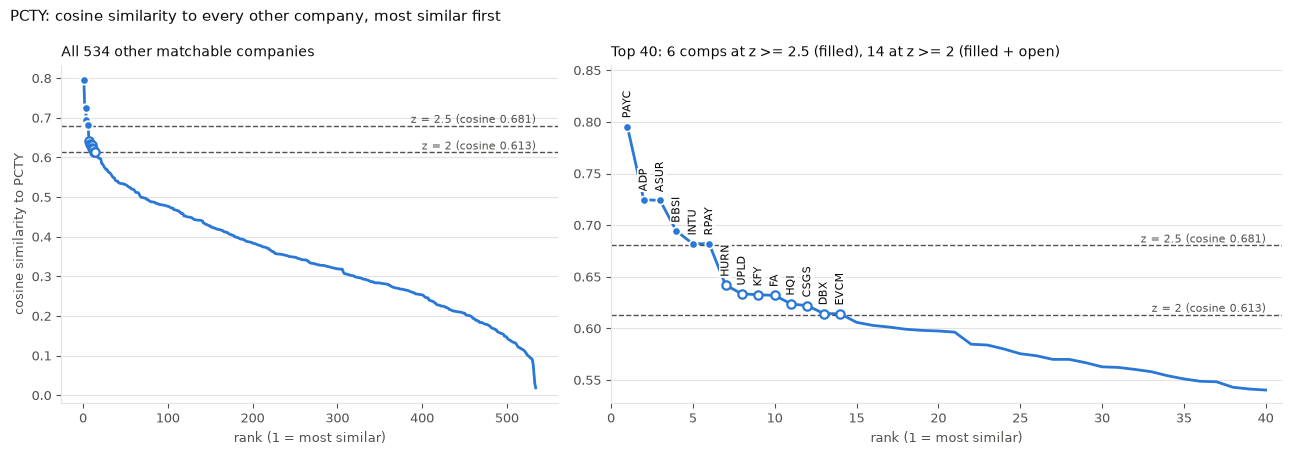

PCTY's cosine with the other 534 companies: mean 0.345, SD 0.134
z = 2 at cosine 0.613: 14 comps
z = 2.5 at cosine 0.681: 6 comps


In [9]:
import matplotlib.pyplot as plt

i_t = tickers.index(TARGET)
row = np.delete(S[i_t], i_t)
cuts = {lvl: row.mean() + lvl * row.std() for lvl in Z_LEVELS}   # the cosine where z = each level
ranked = ranking(TARGET)
ranked.to_csv(RUN_DIR / f"comps_{TARGET}.csv", index=False)
z_lo, z_hi = min(Z_LEVELS), max(Z_LEVELS)

BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
ZOOM = 40
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
for ax, n in zip(axes, [len(ranked), ZOOM]):
    r = ranked.head(n)
    ax.plot(r["rank"], r.cosine, color=BLUE, lw=2)
    strict, loose = r[r.z >= z_hi], r[(r.z >= z_lo) & (r.z < z_hi)]
    ax.scatter(strict["rank"], strict.cosine, s=36, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(loose["rank"], loose.cosine, s=36, color=SURFACE, edgecolor=BLUE, linewidth=1.6, zorder=3)
    for lvl, cut in cuts.items():
        ax.axhline(cut, color=MUTED, lw=1, ls="--")
        ax.text(n, cut, f"z = {lvl:g} (cosine {cut:.3f})", ha="right", va="bottom", color=MUTED, fontsize=8)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.set_xlabel("rank (1 = most similar)", color=MUTED, fontsize=9)
axes[0].set_ylabel(f"cosine similarity to {TARGET}", color=MUTED, fontsize=9)
axes[0].set_title(f"All {len(ranked)} other matchable companies", loc="left", color=INK, fontsize=10)
axes[1].set_title(f"Top {ZOOM}: {(ranked.z >= z_hi).sum()} comps at z >= {z_hi:g} (filled), "
                  f"{(ranked.z >= z_lo).sum()} at z >= {z_lo:g} (filled + open)",
                  loc="left", color=INK, fontsize=10)
axes[1].set_xlim(0, ZOOM + 1)
axes[1].set_ylim(top=ranked.cosine.max() + 0.06)
for _, c in ranked[ranked.z >= z_lo].iterrows():
    axes[1].annotate(c.ticker, (c["rank"], c.cosine), xytext=(0, 6), textcoords="offset points",
                     rotation=90, ha="center", va="bottom", fontsize=8, color=INK,
                     bbox=dict(fc=SURFACE, ec="none", pad=0.6))
fig.suptitle(f"{TARGET}: cosine similarity to every other company, most similar first",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(RUN_DIR / f"cosine_falloff_{TARGET}.png", dpi=150)
plt.show()

print(f"{TARGET}'s cosine with the other {len(row)} companies: mean {row.mean():.3f}, SD {row.std():.3f}")
for lvl, cut in cuts.items():
    print(f"z = {lvl:g} at cosine {cut:.3f}: {(ranked.z >= lvl).sum()} comps")

### 3.3 Checks

- **SIC check, all companies:** for every matchable company, take its 5 most
  similar companies and count how many share its SIC code, at each level of
  the hierarchy (SIC4 industry, SIC3 industry group, SIC2 major group, and
  Division, e.g. Manufacturing = SIC2 20-39); average over all companies.
  "If neighbours were random" is the same share for 5 companies picked at
  random. Weak: SIC is coarse and sometimes wrong.
- **Text length:** Spearman correlation between a company's word count and
  the mean cosine of its top 5. A high value means longer sites look more
  similar to everything.

In [10]:
D = S.copy()
np.fill_diagonal(D, -np.inf)
top5 = np.argsort(-D, axis=1)[:, :5]
# SIC hierarchy: division (letter, a range of 2-digit groups) > SIC2 major group > SIC3 industry group > SIC4 industry
DIVISIONS = [(1, 9, "A Agriculture, Forestry, Fishing"), (10, 14, "B Mining"), (15, 17, "C Construction"),
             (20, 39, "D Manufacturing"), (40, 49, "E Transportation, Communications, Utilities"),
             (50, 51, "F Wholesale Trade"), (52, 59, "G Retail Trade"),
             (60, 67, "H Finance, Insurance, Real Estate"), (70, 89, "I Services"),
             (91, 97, "J Public Administration"), (99, 99, "K Nonclassifiable")]
def sic_division(sic2):
    return next((name for lo, hi, name in DIVISIONS if lo <= int(sic2) <= hi), "unknown")
universe["sic_division"] = universe["target_sic2_code"].map(sic_division)

sic_rows = []
for col, level in [("target_sic4_code", "SIC4 (industry)"), ("target_sic3_code", "SIC3 (industry group)"),
                   ("target_sic2_code", "SIC2 (major group)"), ("sic_division", "Division")]:
    sic = universe[col].values
    chance = np.mean([(sic == s).sum() - 1 for s in sic]) / (len(sic) - 1)
    rate = (sic[top5] == sic[:, None]).mean()
    sic_rows.append({"level": level, "% of top-5 neighbours with same code": round(100 * rate, 1),
                     "% if neighbours were random": round(100 * chance, 1),
                     "times better than random (lift)": round(rate / chance, 1)})
sic_check = pd.DataFrame(sic_rows).set_index("level")
sic_check.to_csv(RUN_DIR / "sic_check.csv")
display(sic_check)

length_bias = pd.Series(np.take_along_axis(S, top5, axis=1).mean(axis=1)).corr(universe.words, method="spearman")
print(f"Spearman(word count, mean top-5 cosine) = {length_bias:.2f}")

,% of top-5 neighbours with same code,% if neighbours were random,times better than random (lift)
level,,,
SIC4 (industry),24.3,1.7,14.2
SIC3 (industry group),35.4,3.4,10.5
SIC2 (major group),48.3,7.2,6.7
Division,68.3,27.1,2.5


Spearman(word count, mean top-5 cosine) = 0.34


### 3.4 Valuation

The financial fields are loaded here for the first time, after the comps are
fixed: only `target_ev_to_ebitda`, read from the same snapshot and joined to
the comps on `IQ_COMPANY_ID`. The target's multiple is estimated, at each
z level, as the **median** of its comps' EV/EBITDA (the mean is shown too; one high multiple
pulls it up), and compared with the target's actual multiple in the list.
The last row uses every other matchable company with no matching at all:
the number matching has to beat. Comps without a positive multiple would be
left out and counted.

In [11]:
ev = (pd.read_csv(snapshot_path(), dtype=str, usecols=["IQ_COMPANY_ID", "target_ev_to_ebitda"])
      .set_index("IQ_COMPANY_ID").target_ev_to_ebitda.pipe(pd.to_numeric, errors="coerce"))
id_of = dict(zip(universe.target_ciq_ticker, universe.IQ_COMPANY_ID))
actual = ev[id_of[TARGET]]

comp_sets = {f"comps (z >= {lvl:g})": target_comps[target_comps[col]].ticker          # strictest level first
             for lvl, col in sorted(LEVEL_COLS.items(), reverse=True)}
comp_sets["all other matchable companies (no matching)"] = ranked.ticker
rows = []
for name, comp_tickers in comp_sets.items():
    m = ev.reindex([id_of[x] for x in comp_tickers])
    valid = m[m > 0]
    est = valid.median()
    rows.append({"comp set": name, "comps": len(valid), "left out (no positive multiple)": len(m) - len(valid),
                 "median EV/EBITDA": est, "mean EV/EBITDA": valid.mean(),
                 "25th pct": valid.quantile(0.25), "75th pct": valid.quantile(0.75),
                 f"{TARGET} actual": actual, "median - actual": est - actual,
                 "median - actual (% of actual)": 100 * (est - actual) / actual})
rows.append({"comp set": f"{TARGET} actual", "median EV/EBITDA": actual})   # last row: what the estimates aim at
valuation = pd.DataFrame(rows).set_index("comp set").round(2)
valuation = valuation.astype({"comps": "Int64", "left out (no positive multiple)": "Int64"})
valuation.to_csv(RUN_DIR / f"valuation_{TARGET}.csv")

valuation_comps = (target_comps.assign(ev_to_ebitda=lambda d: [ev[id_of[x]] for x in d.ticker])
                   [["rank", "ticker", "company", "sic4", "cosine", "z", *LEVEL_COLS.values(), "ev_to_ebitda"]])
valuation_comps.to_csv(RUN_DIR / f"valuation_comps_{TARGET}.csv", index=False)

print(f"{TARGET} ({t.target_company_name}): actual EV/EBITDA {actual:.2f}")
display(valuation.astype(object).where(valuation.notna(), ""))
display(valuation_comps.set_index("rank").round({"z": 2, "ev_to_ebitda": 2}))

PCTY (Paylocity Holding Corporation): actual EV/EBITDA 22.13


,comps,left out (no positive multiple),median EV/EBITDA,mean EV/EBITDA,25th pct,75th pct,PCTY actual,median - actual,median - actual (% of actual)
comp set,,,,,,,,,
comps (z >= 2.5),6,0,14.87,15.82,11.27,20.49,22.13,-7.25,-32.78
comps (z >= 2),14,0,13.54,14.43,10.84,18.92,22.13,-8.59,-38.83
all other matchable companies (no matching),534,0,10.84,12.53,7.24,15.6,22.13,-11.28,-50.99
PCTY actual,,,22.13,,,,,,


,ticker,company,sic4,cosine,z,comp_z2,comp_z2.5,ev_to_ebitda
rank,,,,,,,,
1,PAYC,"Paycom Software, Inc.",7370,0.7955,3.36,True,True,12.69
2,ADP,"Automatic Data Processing, Inc.",7374,0.7247,2.83,True,True,17.05
3,ASUR,"Asure Software, Inc.",7370,0.7239,2.82,True,True,21.64
4,BBSI,"Barrett Business Services, Inc.",7363,0.6942,2.60,True,True,10.80
5,INTU,Intuit Inc.,7372,0.6820,2.51,True,True,23.77
6,RPAY,Repay Holdings Corporation,7389,0.6820,2.51,True,True,8.93
7,HURN,Huron Consulting Group Inc.,8742,0.6419,2.21,True,False,15.66
8,UPLD,"Upland Software, Inc.",7370,0.6335,2.15,True,False,8.07
9,KFY,Korn Ferry,7361,0.6326,2.14,True,False,7.31


In [12]:
run_info = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "method": "method 1: mean-pooled chunk embeddings of cleaned page text, cosine similarity",
    "snapshot": SNAPSHOT, "snapshot_sha256": manifest["snapshots"][SNAPSHOT]["sha256"],
    "page_text_dir": str(page_dir), "embed_model": EMBED_MODEL, "chunk_words": CHUNK_WORDS,
    "min_words": MIN_WORDS, "name_masking": False, "template_sentence_removal": False,
    "matchable": len(universe), "excluded": len(excluded), "embedding_cache": embed_cache.name,
    "z_levels": Z_LEVELS, "comps_per_company": n_comps.describe().round(2).to_dict(),
    "target": TARGET, "target_level_cosines": {f"z{lvl:g}": round(float(c), 4) for lvl, c in cuts.items()},
    "target_comps": {col: int(target_comps[col].sum()) for col in LEVEL_COLS.values()}, "sic_check": sic_check.reset_index().to_dict("records"),
    "spearman_words_vs_top5_cosine": round(float(length_bias), 3),
    "valuation": valuation.reset_index().to_dict("records"),
}
(RUN_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str), encoding="utf-8")
print("saved:", sorted(p.name for p in RUN_DIR.iterdir()))

saved: ['all_comps.csv', 'comps_PCTY.csv', 'cosine_falloff_PCTY.png', 'excluded_companies.csv', 'run_info.json', 'sic_check.csv', 'similarity_matrix.csv', 'universe_text.csv', 'valuation_PCTY.csv', 'valuation_comps_PCTY.csv']


## 4. Method 2

_To be filled in._